<h1> Exemplos práticos de otimização de portfólio com computação clássica e quântica </h1>

Esse notebook é um suporte ao nosso artigo na RBEF. 

<a href="https://doi.org/10.1590/1806-9126-RBEF-2022-0099" target="_blank"> Artigo em PDF</a>

# Portfólio ou Carteira

A **carteira** ou **portfólio** de um investidor é basicamente o seu investimento em diferentes tipos de ativos.

Por exemplo, se você tem investimentos (ações) em 5 empresas, digamos: Google, Amazon, Tesla, Petrobras e Vale. Além disso, algum investimento em criptomoedas: Bitcoin e Ethereum. 

Essas 5 empresas mais as 2 criptomoedas compõem sua carteira de investimentos.

# Ativos, Retorno e Risco

**Ativos** pode ser de vários tipos. São exemplos de ativos (lista não euxastiva):

- Ações
- Criptomoedas (e. g. Bitcoin - BTC)
- Dinheiro
- Cota de fundos de investimento
- Títulos do Tesouro

Normalmente, quando você constrói um portfólio, é aconselhável diversificar seus ativos ou comprar diferentes tipos de ativos de diferentes empresas. Para todos os ativos, você obterá lucro após um período de tempo especificado. No entanto, o lucro pode não ser o mesmo para cada investimento feito.

Esse lucro, ou prejuízo, é o que chamamos de **retorno**. Por exemplo, você obterá retornos de ações quando o valor de mercado subir e/ou com a distribuição de lucros "em dinheiro" na forma de dividendos.

Há diversos aspectos de **risco**, como falência das empresas, recuperação judicial, risco regulatório etc. Para o contexto de gestão de portfólio interessa o risco associado às flutuações no valor do ativo, ou volatilidade do ativo. Para certos ativos, seu valor é altamente volátil, ou seja, o valor flutua bastante, e. g. Bitcoin. Enquanto alguns outros ativos, como títulos do governo e certas ações são mais estáveis, sendo relativamente mais resistentes às condições de mercado, mas podem dar retornos menores em comparação com aqueles de alto risco.


In [33]:
import plotly.io as pio
pio.renderers.default = 'iframe'

In [34]:
# Importando pacotes úteis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import yfinance as yf

%matplotlib inline


def plot_interativo(dados, titulo=None, ylabel=None):
    """Gráfico de linhas interativo (Plotly): uma curva por coluna do DataFrame, com as datas (índice) no eixo x."""
    fig = px.line(dados, title=titulo)
    fig.update_layout(xaxis_title="Data", yaxis_title=ylabel, legend_title_text="Ativo",
                      width=1000, height=500)
    fig.show()

In [35]:
# Exemplo de leitura de dados financeiros dos ativos com o yfinance
#
# Obs1: O ticker das ações brasileiras precisa de um ".SA" para a API funcionar.
#       Os preços estão em Reias (BRL). É interessante não analisar junto
#       com ativos em dólar (USD) ou fazer conversão.
# Obs2: O mercado de cripto funciona 24 horas, todos os dias, não só os úteis.
#       Assim, é interessante analisar separadamente ou com exclusão
#       de fim de semanas ou feriados para evitar "NaN" dos demais ativos.
# Obs3: Na versão atual do yfinance o padrão é auto_adjust=True (preços já ajustados por dividendos e
#       desdobramentos, e sem a coluna 'Adj Close'). Aqui usamos auto_adjust=False para manter o comportamento
#       do notebook original, em que 'Close' é o fechamento ajustado apenas por desdobramentos.
#       Use auto_adjust=True se preferir retornos totais (com dividendos).
# Obs4: A data final é exclusiva (o último dia baixado é o anterior a data_final).
#
# Parâmetros de entrada da API: lista de ativos, data inicial, data final
ativos       = "BTC-USD"    # Bitcoin
data_inicial = "2020-01-01" # formato: YYYY-MM-DD (Ano-Mês-Dia)
#data_final   = "2021-09-20"
# Saída: pandas DataFrame com dados de Open, High, Low, Close, Adj Close e Volume.
#        Da data mais antiga a mais recente (de cima para baixo)
teste        = yf.download(ativos, start=data_inicial, end="2021-09-20", auto_adjust=False, progress=False)
# Nas versões recentes do yfinance as colunas vêm em MultiIndex (preço, ticker), mesmo com um único ativo.
# Aqui deixamos só o nível do preço:
if isinstance(teste.columns, pd.MultiIndex):
    teste.columns = teste.columns.get_level_values(0)
teste

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2020-01-01,7200.174316,7200.174316,7254.330566,7174.944336,7194.892090,18565664997
2020-01-02,6985.470215,6985.470215,7212.155273,6935.270020,7202.551270,20802083465
2020-01-03,7344.884277,7344.884277,7413.715332,6914.996094,6984.428711,28111481032
2020-01-04,7410.656738,7410.656738,7427.385742,7309.514160,7345.375488,18444271275
2020-01-05,7411.317383,7411.317383,7544.497070,7400.535645,7410.451660,19725074095
...,...,...,...,...,...,...
2021-09-15,48176.347656,48176.347656,48450.468750,46773.328125,47098.000000,30484496466
2021-09-16,47783.359375,47783.359375,48486.828125,47079.558594,48158.906250,31764293754
2021-09-17,47267.519531,47267.519531,48160.921875,46832.523438,47771.003906,28727713711


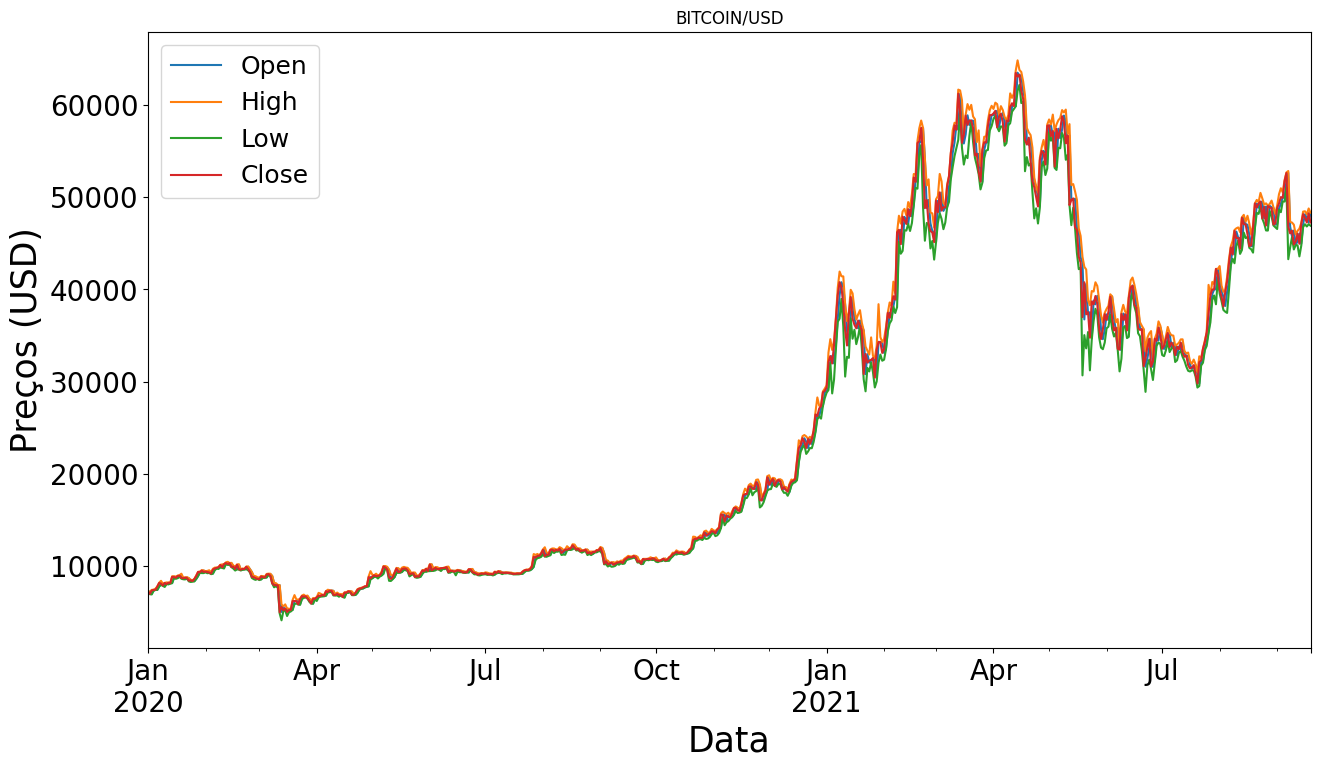

In [36]:
# Plot dos preços de 'Open', 'High', 'Low', 'Close' de um ativo
colunas = ['Open', 'High', 'Low', 'Close']
teste[colunas].plot(figsize=[15,8], title = 'BITCOIN/USD')
plt.xlabel('Data',  fontsize=25)
plt.ylabel('Preços (USD)',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc = 'best', fontsize=18);
plt.show()

In [37]:
#Plot OHLC Interativo
plot_interativo(teste[colunas], 'BITCOIN/USD', 'Preços (USD)')

In [65]:
# Consultando vários ativos
# Escolha uma lista de ativos
# Ações brasileiras
ativos       = ["MATD3.SA","DIRR3.SA","ECOR3.SA","OFSA3.SA","GOAU3.SA","BOVX11.SA"]
#Obs: o símbolo das ações brasileiras precisam de um ".SA" para a API funcionar
# Ações americanas
#ativos =  ['META','AMZN','NFLX','GOOGL']   # FANG -> Meta (antigo Facebook, ticker 'FB'), Amazon, Netflix e Google -> cotação em dólar
#  Ou
#ativos =  ['AAPL', 'NKE', 'GOOGL', 'AMZN'] # Apple, Nike, Google e Amazon -> cotação em dólar
# Criptomoedas
#ativos = ['BTC-USD', 'ETH-USD']  # Criptomoedas    -> cotação em dólar
#
df  =  yf.download(ativos, start=data_inicial, auto_adjust=False, progress=False)
df.head()

Price      Adj Close                                                     \
Ticker     BOVX11.SA  DIRR3.SA   ECOR3.SA  GOAU3.SA MATD3.SA   OFSA3.SA   
Date                                                                      
2020-01-02       NaN  3.160955  14.255210  3.734316      NaN  36.217480   
2020-01-03       NaN  3.158916  14.141519  3.701772      NaN  36.674355   
2020-01-06       NaN  3.118156  14.062809  3.648890      NaN  36.715889   
2020-01-07       NaN  3.136499  14.377649  3.648890      NaN  36.798954   
2020-01-08       NaN  3.154840  14.412632  3.636686      NaN  36.882030   

Price          Close                                 ...       Open            \
Ticker     BOVX11.SA  DIRR3.SA   ECOR3.SA  GOAU3.SA  ...   ECOR3.SA  GOAU3.SA   
Date                                                 ...                        
2020-01-02       NaN  5.148692  16.099194  6.885172  ...  16.346113  6.660166   
2020-01-03       NaN  5.145372  15.970796  6.825170  ...  16.000425  6.705167   
2020-01-06       NaN  5.078980  15.881904  6.727668  ...  15.960919  6.855171   
2020-01-07       NaN  5.108857  16.237471  6.727668  ...  15.951042  6.787669   
2020-01-08       NaN  5.138733  16.276978  6.705167  ...  16.306606  6.727668   

Price                             Volume                                      \
Ticker     MATD3.SA   OFSA3.SA BOVX11.SA DIRR3.SA ECOR3.SA GOAU3.SA MATD3.SA   
Date                                                                           
2020-01-02      NaN  43.490002       NaN  3632069  2396118   150662      NaN   
2020-01-03      NaN  42.299999       NaN  3202800  4632367   127196      NaN   
2020-01-06      NaN  44.150002       NaN  3487172  2461929   108397      NaN   
2020-01-07      NaN  44.500000       NaN  2713282  3544465    40532      NaN   
2020-01-08      NaN  44.299999       NaN  3167253  4957979    56931      NaN   

Price                
Ticker     OFSA3.SA  
Date                 
2020-01-02    18100  
2020-01-03    18300  
2020-01-06    24700  
2020-01-07    18200  
2020-01-08    11900  

[5 rows x 36 columns]

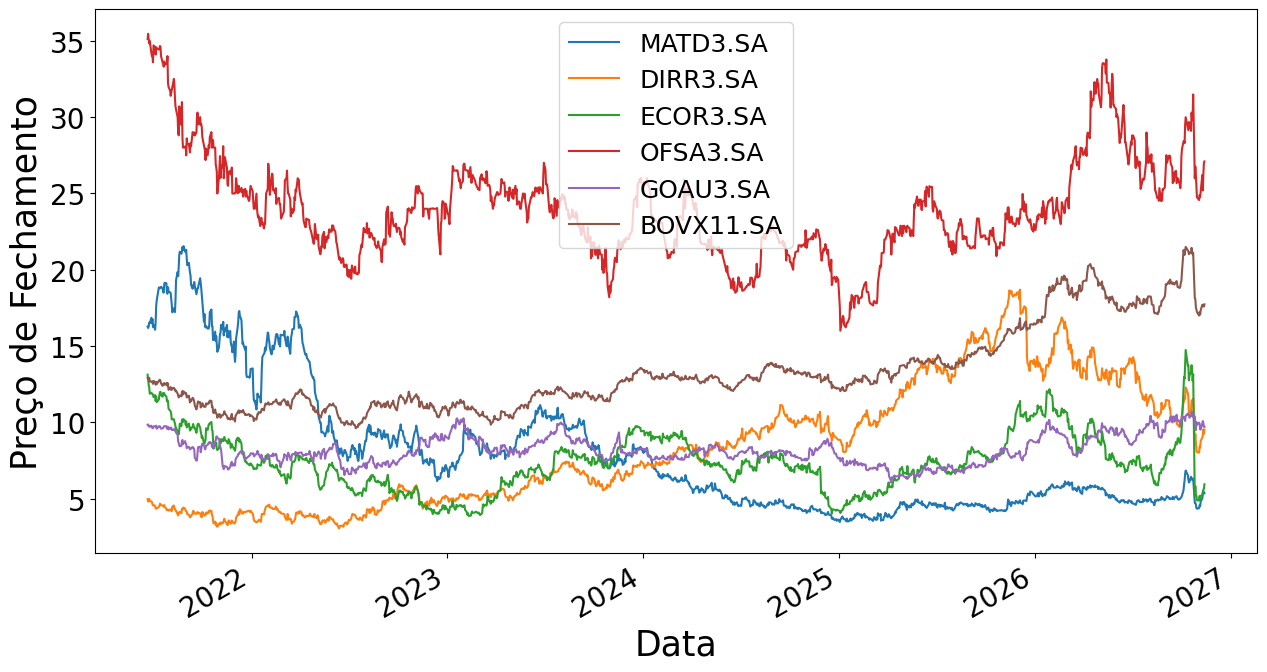

In [66]:
#Plot
# Selecionando só preço de fechamento
# - o yfinance devolve as colunas em ordem alfabética; "[ativos]" restaura a ordem da lista definida acima
# - dropna() mantém só os dias em que todos os ativos têm cotação
df    = df['Close'][ativos].dropna()
#
df.plot(figsize=[15,8])
plt.xlabel('Data',  fontsize=25)
plt.ylabel('Preço de Fechamento',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc = 'best', fontsize=18);
plt.show()

In [67]:
#Plot interativo de vários ativos
plot_interativo(df, 'Preço de fechamento', 'Preço de Fechamento')

<font color="blue"> Note a diferença de escala dos valores das ações. Uma prática corriqueira é tomar o "log". </font>

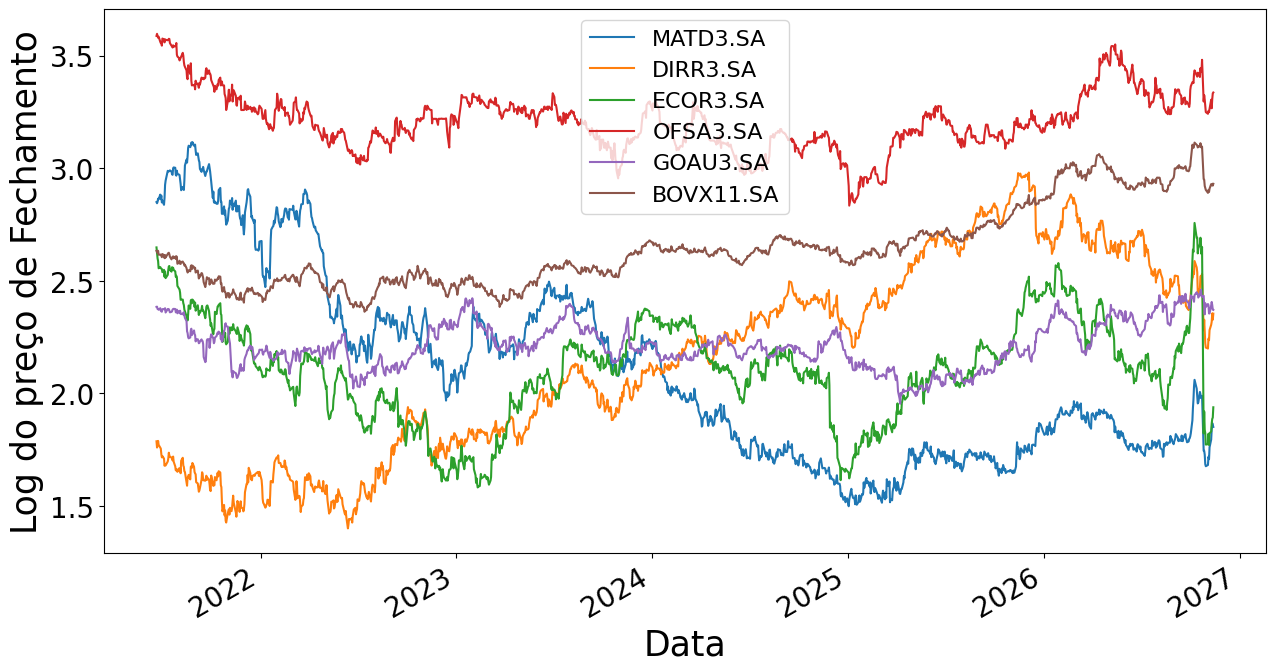

In [68]:
np.log(df + 1).plot(figsize=[15,8]) # "+1" evita logaritmando negativo para ações cotadas abaixo de "1"
plt.xlabel('Data',  fontsize=25)
plt.ylabel('Log do preço de Fechamento',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc = 'best', fontsize=16);
plt.show()

In [69]:
#Plot interativo
plot_interativo(np.log(df + 1), 'Log do preço de fechamento', 'Log do preço de Fechamento')

# Otimização de portfólio

Um bom portfólio é aquele que nos dá o máximo retorno com o mínimo de risco. Porém, como decidimos, entre as infinitas combinações possíveis de carteiras, aquela que é ótima? Ou seja, como é feita a otimização de portfólio?

A Teoria Moderna do Portfólio, formulada por H. Markowitz, também conhecida como análise de variância média, é um processo matemático que permite ao usuário maximizar os retornos para um determinado nível de risco.

A teoria assume que todos os investidores são avessos ao risco, ou seja, se houver uma escolha entre carteiras de baixo e alto riscos com os mesmos retornos, um investidor escolherá uma com baixo risco.

De um modo geral, a teoria incentiva a diversificação de ativos. Ele diz que um ativo A de alta variação, se combinado com diversos ativos B e C, onde A, B e C têm pouca ou nenhuma correlação, pode nos dar uma carteira com baixa variação de retornos. Este é um ponto crucial da Teoria. Outro ponto crucial é mostrar que buscar maiores retornos significa se expor a mais risco (volatilidade).


# Fronteira Eficiente

Sabemos que cada ativo em uma carteira tem sua própria taxa de retorno e riscos esperados. É possível criar várias combinações de ativos que podem fornecer retornos elevados para um nível de risco predefinido. Da mesma forma, pode haver várias carteiras que oferecem o menor risco para um retorno esperado predefinido.

Fronteira eficiente é determinada através do gráfico com 'retornos' (Y) versus 'volatilidade' (X). Mostra o conjunto de carteiras ideais que oferecem o maior retorno esperado para um determinado nível de risco ou o menor risco para um determinado nível de retorno esperado.

As carteiras que estão abaixo da fronteira eficiente são sub-ótimas porque não fornecem retorno suficiente para o nível de risco ou têm um risco maior para a taxa de retorno definida.

Você aprenderá a reproduzir a fronteira eficiente abaixo!

![picture](https://www.dualq.tech/wp-content/uploads/fronteira_vf4.png)

# Conceitos Fundamentais em Otimização de Portfólio

- **Retornos esperados**

Os retornos esperados de um ativo são simplesmente a média da variação percentual nos preços de suas ações. Portanto, o valor do retorno esperado que obtemos aqui são os retornos esperados diários. Para um valor de retorno anual esperado, você precisará reamostrar os dados a cada ano, como verá mais adiante.

O retorno do dia $i$, $R_i$, é definido como:

$R_i =  (p_i - p_{i-1}) /p_{i-1}$,
aqui calculamos a variação percentual entre o preço do dia $i$ e do dia $i-1$.

Podemos generalizar para o retorno entre o dia $i$ e o dia $j$ fazendo,

$R_{ij} =  (p_i - p_{j}) /p_{j}$. Como há cerca de $250$ (para criptomoedas use $365$). o retorno anual pode ser aproximado por

$R_{anual} = (p_i - p_{i-250}) /p_{i-250}$.


O retorno logarítmico é definido como

$r_i =  ln(p_i/p_{i-1})$, ou, de modo geral

$r_{ij} =  ln(p_i) - ln(p_{j})$. Uma vantagem é ser adtivo no tempo. Note que $r_{31} = r_{32} + r_{21}$.







In [70]:
# Variação percentual diária ou retorno diário
# (fill_method=None: não preenche valores ausentes; é o comportamento padrão nas versões atuais do pandas)
retorno = df.pct_change(fill_method=None)#.apply(lambda x: np.log(1+x))
retorno

Ticker,MATD3.SA,DIRR3.SA,ECOR3.SA,OFSA3.SA,GOAU3.SA,BOVX11.SA
Date,,,,,,
2021-06-21,NaN,NaN,NaN,NaN,NaN,NaN
2021-06-22,-0.005528,-0.032688,-0.027418,0.009394,0.000761,-0.006966
2021-06-23,0.006794,0.013793,-0.024276,-0.010434,-0.011407,-0.002338
2021-06-24,0.014724,0.021769,-0.012841,-0.007409,0.000000,0.009375
2021-06-25,-0.002418,-0.020639,-0.034146,0.004881,-0.003846,-0.018576
...,...,...,...,...,...,...
2026-11-09,0.041494,0.026166,0.009634,0.042562,0.039832,0.021338
2026-11-10,0.055777,0.015521,0.043893,-0.038535,0.017137,-0.005082
2026-11-11,0.033962,0.041485,0.023766,0.042857,-0.014866,0.003405


<font  color="blue"> Observe que a primeira linha apresenta NaN (Not a Number), pois a variação percentual (retorno) só é definida a partir do segundo ponto (dia, neste caso) de um dado intervalo. </font>



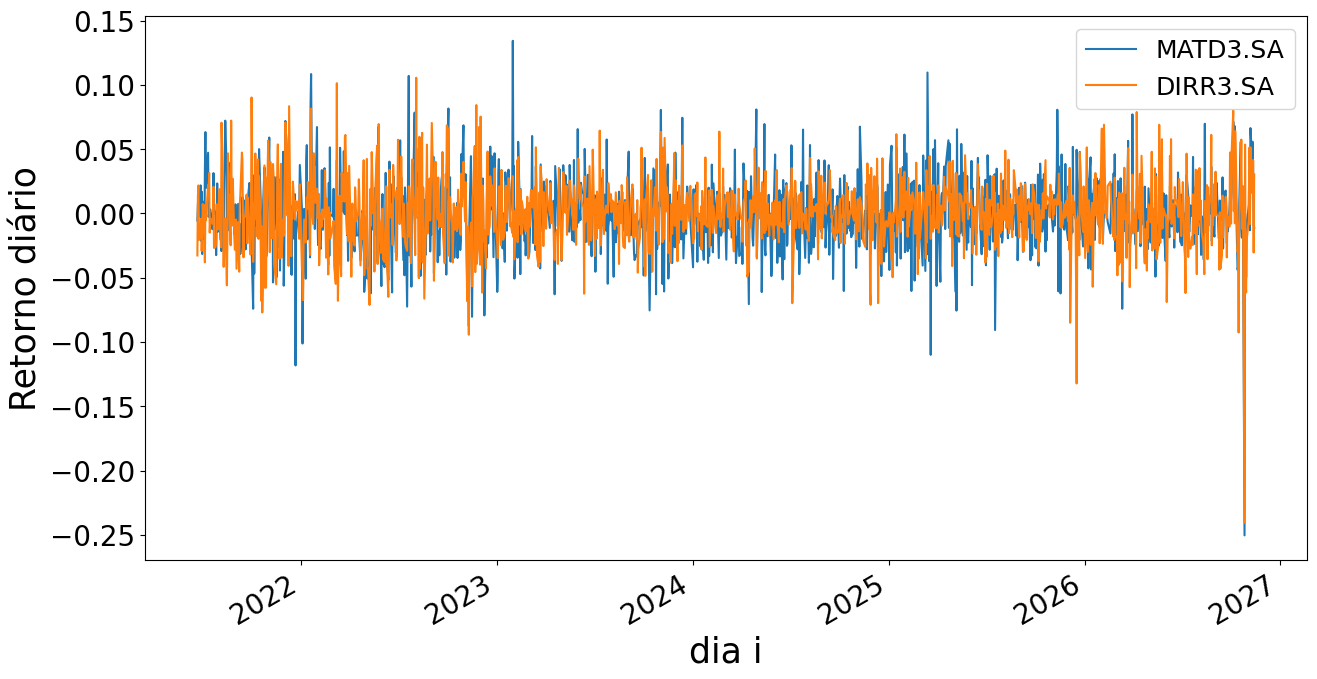

In [71]:
#Plot do retorno diário dos n primeiros ativos
n = 2
retorno[ativos[0:n]].plot(figsize=[15,8]) #n ativos
plt.xlabel('dia i',  fontsize=25)
plt.ylabel('Retorno diário',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc = 'best', fontsize=18);
plt.show()

In [72]:
log_retorno = np.log(df/df.shift())
#log_retorno = df.pct_change().apply(lambda x: np.log(1+x))
log_retorno

Ticker,MATD3.SA,DIRR3.SA,ECOR3.SA,OFSA3.SA,GOAU3.SA,BOVX11.SA
Date,,,,,,
2021-06-21,NaN,NaN,NaN,NaN,NaN,NaN
2021-06-22,-0.005544,-0.033235,-0.027801,0.009350,0.000761,-0.006990
2021-06-23,0.006771,0.013699,-0.024575,-0.010489,-0.011472,-0.002341
2021-06-24,0.014617,0.021535,-0.012924,-0.007437,0.000000,0.009331
2021-06-25,-0.002421,-0.020855,-0.034743,0.004869,-0.003854,-0.018751
...,...,...,...,...,...,...
2026-11-09,0.040656,0.025830,0.009588,0.041681,0.039059,0.021113
2026-11-10,0.054277,0.015402,0.042957,-0.039297,0.016992,-0.005095
2026-11-11,0.033398,0.040647,0.023488,0.041964,-0.014978,0.003399


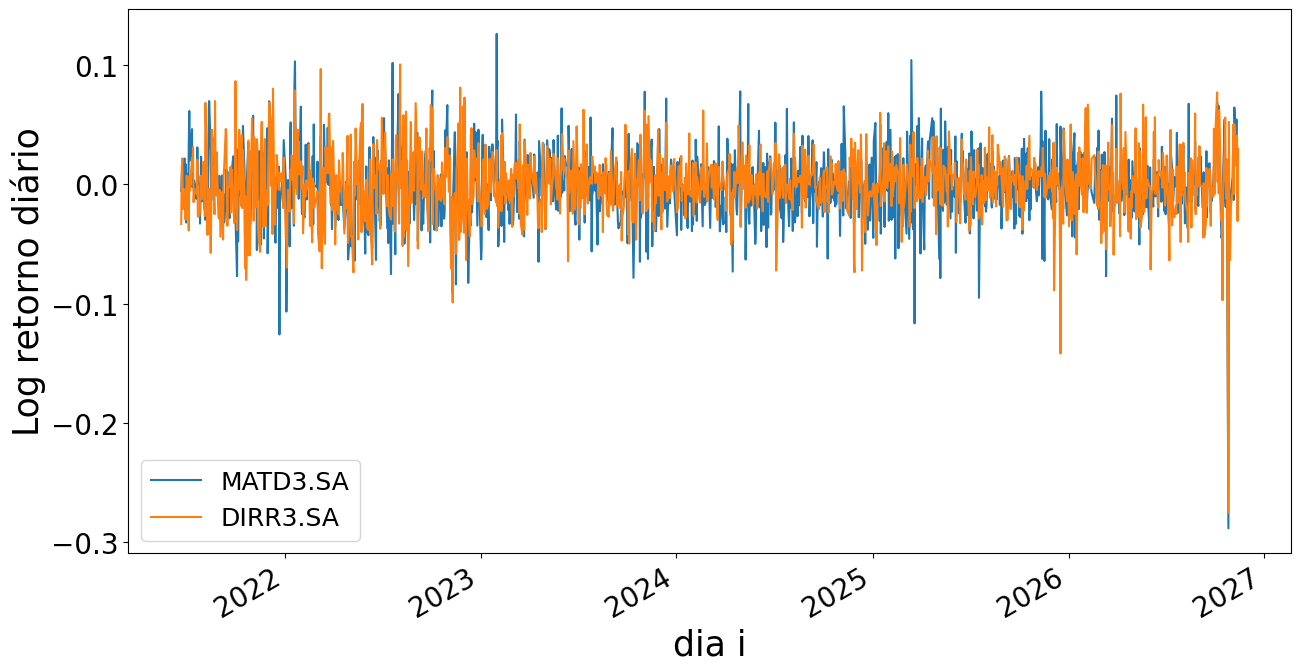

In [73]:
#Plot do retorno logarítmico diário dos n primeiros ativos
n = 2
log_retorno[ativos[0:n]].plot(figsize=[15,8]) #n ativos
plt.xlabel('dia i',  fontsize=25)
plt.ylabel('Log retorno diário',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc = 'best', fontsize=18);
plt.show()

- **Variância**

A Variância nos preços das ações de uma empresa é um indicador importante de quão volátil esse investimento será, ou seja, como os retornos podem flutuar.

$\sigma^2 =  \frac{1}{N-1} \sum_{i = 1}^N (R_i - \mu)^2$

onde $R_i$ é o retorno do dia $i$ e $\mu$ é o retorno esperado (retorno médio).

In [74]:
# Cálculo da variança com '.var'
varianca = retorno.var()
varianca

Ticker
MATD3.SA     0.000843
DIRR3.SA     0.000728
ECOR3.SA     0.001171
OFSA3.SA     0.000497
GOAU3.SA     0.000361
BOVX11.SA    0.000147
dtype: float64

- **Volatilidade**

A volatilidade é medida como o desvio padrão das ações de uma empresa:

$\sigma = \sqrt{  \frac{1}{N-1} \sum_{i = 1}^N (R_i - \mu)^2 }$

- **Volatilidade Anual**


O que obtemos da raiz quadrada da variância é o desvio padrão diário (os dados são diários). Para convertê-lo em desvio padrão anual, multiplicamos a variância por $250$ (número médio de dias de negociação em um ano).

In [75]:
# Volatilidade anual
volatld = np.sqrt(varianca * 250) # Para criptomoedas use 365, pois as negociações ocorrem todo dia.
volatld

Ticker
MATD3.SA     0.459142
DIRR3.SA     0.426646
ECOR3.SA     0.541173
OFSA3.SA     0.352315
GOAU3.SA     0.300352
BOVX11.SA    0.191726
dtype: float64

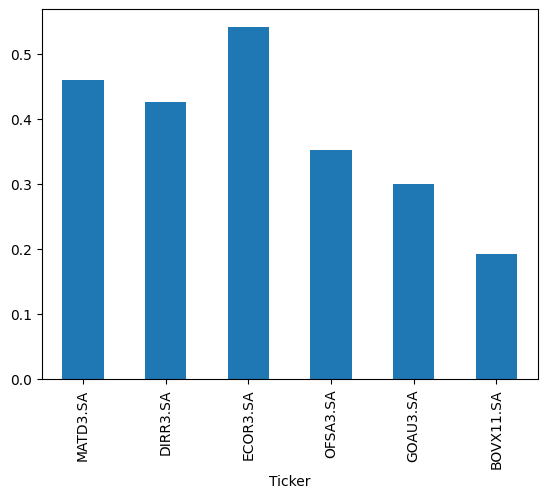

In [76]:
#Plot - volatilidade anual
volatld.plot(kind='bar');

- **Covariância**

A covariância mede a relação direcional entre os retornos de dois ativos.

Uma covariância positiva significa que os **retornos** dos dois ativos se movem juntos (ambos caem ou sobem), enquanto uma covariância negativa significa que eles se movem inversamente (quando um sobe ou outro tende a cair e vice versa). O risco (assumido como a volatilidade) pode ser reduzido em uma carteira combinando ativos que têm uma covariância negativa.


In [77]:
cov_matrix = df.pct_change(fill_method=None).cov() # Sem log of percentage change
cov_matrix = cov_matrix.dropna()
# Matriz covariante
#cov_matrix = df.pct_change().apply(lambda x: np.log(1+x)).cov() # Log of percentage change
cov_matrix

Ticker,MATD3.SA,DIRR3.SA,ECOR3.SA,OFSA3.SA,GOAU3.SA,BOVX11.SA
Ticker,,,,,,
MATD3.SA,0.000843,0.000372,0.000491,0.000132,0.000109,0.000179
DIRR3.SA,0.000372,0.000728,0.000531,0.000134,0.000102,0.000203
ECOR3.SA,0.000491,0.000531,0.001171,0.000227,0.000137,0.000290
OFSA3.SA,0.000132,0.000134,0.000227,0.000497,0.000057,0.000083
GOAU3.SA,0.000109,0.000102,0.000137,0.000057,0.000361,0.000107
BOVX11.SA,0.000179,0.000203,0.000290,0.000083,0.000107,0.000147


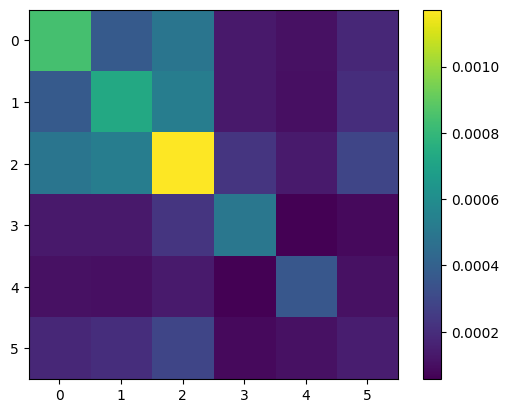

In [78]:
# plot da matriz covariante
plt.imshow(cov_matrix, interpolation='nearest')
plt.colorbar()
plt.show()


- **Correlação**

A correlação, nos setores de finanças e investimento, é uma estatística que mede o grau em que dois títulos se movem em relação um ao outro. As correlações são usadas no gerenciamento avançado de portfólio, calculado como o coeficiente de correlação, que tem um valor entre $-1$ e $+1$. Você pode pensar na correlação como uma versão normalizada da covariância, em que os valores são restritos a estar entre $[-1,+1]$.

Uma correlação de $-1$ significa relação negativa, ou seja, se a correlação entre o Ativo A e o Ativo B for $-1$, se o Ativo A aumentar, o Ativo B diminuirá.

Uma correlação de $+1$ significa relação positiva, ou seja, se a correlação entre o Ativo A e o Ativo B for $+1$, se o Ativo A aumentar, o Ativo B aumenta.

Uma correlação nula, $0$, significa nenhuma relação, ou seja, se a correlação entre o Ativo A e o Ativo B for $0$, eles não têm qualquer correlação um sobre o outro.

In [79]:
# Matriz de correlação
#corr_matrix = df.pct_change().apply(lambda x: np.log(1+x)).corr()
corr_matrix = df.pct_change(fill_method=None).corr()
corr_matrix = corr_matrix.dropna()
corr_matrix

Ticker,MATD3.SA,DIRR3.SA,ECOR3.SA,OFSA3.SA,GOAU3.SA,BOVX11.SA
Ticker,,,,,,
MATD3.SA,1.000000,0.474902,0.494240,0.203797,0.196752,0.509283
DIRR3.SA,0.474902,1.000000,0.574919,0.222303,0.198895,0.619911
ECOR3.SA,0.494240,0.574919,1.000000,0.297984,0.211297,0.697546
OFSA3.SA,0.203797,0.222303,0.297984,1.000000,0.133872,0.308021
GOAU3.SA,0.196752,0.198895,0.211297,0.133872,1.000000,0.466217
BOVX11.SA,0.509283,0.619911,0.697546,0.308021,0.466217,1.000000


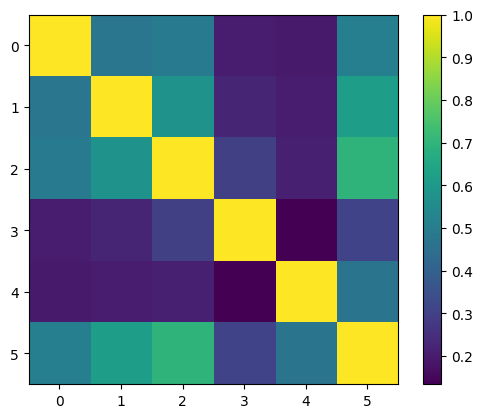

In [80]:
# plot da Matriz de correlação
plt.imshow(corr_matrix, interpolation='nearest')
plt.colorbar()
plt.show()



- **Pesos**

Na abordagem clássica de Markowitz, os pesos representamm a alocação percentual dos investimentos entre os ativos da carteia. Eles devem somar 1 (100% do montante investido). Adiante vamos definir uma matriz de pesos aleatórios para achar a carteira ótima. 

Portanto, o problema de otimização de portfólio nada mais é do que encontrar os valores ótimos dos pesos que maximizam os retornos esperados enquanto minimizam o risco (desvio padrão == volatilidade).

In [81]:
# Exemplo de geração de pesos aleatórios
n_atv = len(ativos)             # Número de ativos
pesos = np.random.random(n_atv) # Escolhendo pesos aleatórios para cada ativo
pesos = pesos/np.sum(pesos)     # Promovendo a normalização
print('ativos: ',ativos)        # Símbolo dos ativos
print('pesos : ',pesos)         # Array de pesos aleatórios

ativos:  ['MATD3.SA', 'DIRR3.SA', 'ECOR3.SA', 'OFSA3.SA', 'GOAU3.SA', 'BOVX11.SA']
pesos :  [0.08668283 0.11589535 0.25493086 0.22012676 0.05295211 0.26941209]




- **Sharpe Ratio (SR)**

Esse índice é o retorno médio obtido em excesso da taxa livre de risco por unidade de volatilidade ou risco total. Como já visto, a volatilidade é uma medida das flutuações de preço de um ativo ou portfólio.

A taxa de retorno livre de risco é o retorno de um investimento com risco zero, o que significa que é o retorno que os investidores poderiam esperar por não correr risco.

A carteira de risco ideal é aquela com o maior Sharpe Ratio. 

$ SR = \frac{R_p - R_f}{\sigma_o}, $

onde:

$R_p$ é o retorno do portfólio, $R_f$ é taxa de lucro livre de risco, ou fator de risco, e $\sigma_p$ é o desvio padrão do portfólio (volatilidade).


No código abaixo, para descobrir o portfólio com Sharpe Ratio máximo, usamos três taxas de retorno livre de risco (três cenários qualitativamente distintos): a taxa de poupança, a CDI  e o IPCA acumulado dos últimos 12 meses.




# Otimização Clássica Irrestrita

Escolhido ativos nos passos anteriores, os ingredientes essencias da abordagem clássica: o retono anual e a volatilidade. Na sequência, geraremos vários portfólios (pesos), dos quais calculamos o retorno e a volatilidade que pretendemos otimizar.

In [82]:
# Retorno anual médio
# ('YE' = fim do ano. O antigo alias 'Y' foi descontinuado no pandas 2.2 e removido no pandas 3.0)
ind_er = df.resample('YE').last().pct_change(fill_method=None).mean()
ind_er

Ticker
MATD3.SA    -0.081183
DIRR3.SA     0.224696
ECOR3.SA     0.247241
OFSA3.SA     0.026801
GOAU3.SA     0.045573
BOVX11.SA    0.121588
dtype: float64

In [83]:
# Volatilidade
# A volatilidade é dada pelo desvio padrão anual. Multiplicamos a volatilidade diária por raiz de 250 (dias de negociação / ano).
# Use 365 ao invés de 250 para criptomoedas
#ann_sd = df.pct_change().apply(lambda x: np.log(1+x)).std().apply(lambda x: x*np.sqrt(250))
ann_sd = df.pct_change(fill_method=None).std().apply(lambda x: x*np.sqrt(250))
ann_sd
vol    = df.pct_change(fill_method=None).std().apply(lambda x: x*np.sqrt(250))
vol

Ticker
MATD3.SA     0.459142
DIRR3.SA     0.426646
ECOR3.SA     0.541173
OFSA3.SA     0.352315
GOAU3.SA     0.300352
BOVX11.SA    0.191726
dtype: float64

In [84]:
assets = pd.concat([ind_er, ann_sd], axis=1) # Criando um DataFrame com retornos e volatilidade dos portfólios
assets.columns = ['Retorno', 'Risco']
assets

,Retorno,Risco
Ticker,,
MATD3.SA,-0.081183,0.459142
DIRR3.SA,0.224696,0.426646
ECOR3.SA,0.247241,0.541173
OFSA3.SA,0.026801,0.352315
GOAU3.SA,0.045573,0.300352
BOVX11.SA,0.121588,0.191726


In [85]:
p_ret    = [] # Define uma "empty list" para os retornos dos portfólios
p_vol    = [] # Define uma "empty list" para a volatilidade dos portfólios
p_pesos  = [] # Define uma "empty list" para os pesos dos ativos no portfólio

num_portfolios = 30000

In [86]:
cov_np = cov_matrix.to_numpy()   # matriz de covariância (dados diários)
er_np  = ind_er.to_numpy()       # retornos anuais esperados

for port in range(num_portfolios):
    pesos = np.random.random(n_atv)       #Escolhendo pesos aleatórios para os ativos
    pesos = pesos/np.sum(pesos)
    p_pesos.append(pesos)
    retornos = np.dot(pesos, er_np)       #Retornos: produto entre os retornos esperados individuais dos ativos e seus pesos
    p_ret.append(retornos)
    var       = pesos @ cov_np @ pesos    #Variância (diária) do portfolio: w^T Σ w
    sd        = np.sqrt(var)              #Desvio padrão diário
    vol_anual = sd*np.sqrt(250)           #Desvio padrão anual  == volatilidade
    p_vol.append(vol_anual)

In [87]:
data = {'Retorno':p_ret, 'Risco':p_vol}

for counter, symbol in enumerate(df.columns.tolist()):
    #print(counter, symbol)
    data['peso '+ symbol] = [w[counter] for w in p_pesos]

In [88]:
portfolios  = pd.DataFrame(data)
portfolios.head(n = 10) # Visualizar os n primeiros portfólio dos 30000 portfolios criados com pesos aleatórios

,Retorno,Risco,peso MATD3.SA,peso DIRR3.SA,peso ECOR3.SA,peso OFSA3.SA,peso GOAU3.SA,peso BOVX11.SA
0,0.061980,0.276893,0.300060,0.086164,0.156461,0.170697,0.146400,0.140218
1,0.042939,0.247344,0.251234,0.082578,0.059247,0.303753,0.195659,0.107529
2,0.066929,0.227819,0.080561,0.024134,0.104993,0.325453,0.304618,0.160242
3,0.066455,0.233078,0.168776,0.063885,0.079800,0.290158,0.131824,0.265557
4,0.129120,0.294824,0.093563,0.258936,0.233502,0.241985,0.086797,0.085217
5,0.060148,0.247462,0.184676,0.061739,0.129602,0.281874,0.262121,0.079988
6,0.023967,0.255510,0.363304,0.003165,0.037880,0.222035,0.105150,0.268466
7,0.127693,0.284162,0.029970,0.054569,0.333213,0.234316,0.172373,0.175558
8,0.096720,0.267295,0.180000,0.189773,0.151247,0.177732,0.132787,0.168461
9,0.116515,0.312142,0.232156,0.309667,0.188407,0.020233,0.153700,0.095837


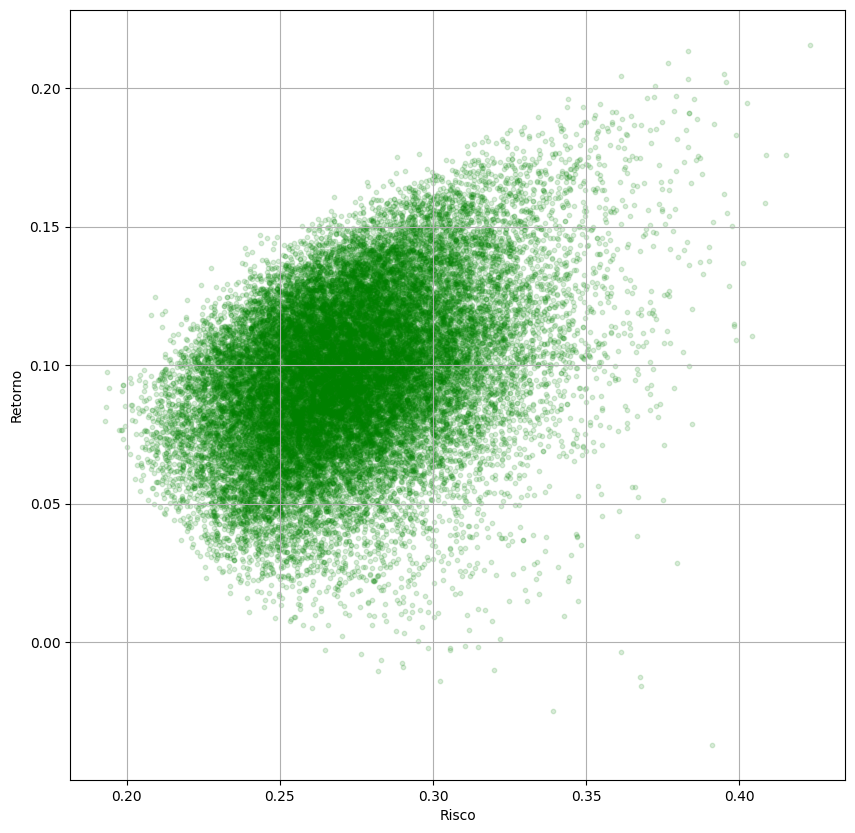

In [89]:
# Plot da Fronteira Eficiente
portfolios.plot.scatter(x='Risco', y='Retorno', c='green', marker='o', s=10, alpha=0.15, grid=True, figsize=[10,10]);

In [90]:
min_vol_port = portfolios.loc[portfolios['Risco'].idxmin()]
# idxmin() retorna o índice do valor mínimo na coluna especificada
min_vol_port

Retorno           0.079827
Risco             0.193043
peso MATD3.SA     0.063790
peso DIRR3.SA     0.023857
peso ECOR3.SA     0.004143
peso OFSA3.SA     0.117047
peso GOAU3.SA     0.272468
peso BOVX11.SA    0.518694
Name: 10577, dtype: float64

In [91]:
max_ret_port = portfolios.loc[portfolios['Retorno'].idxmax()]
# idxmax() retorna o índice do valor máximo na coluna especificada
max_ret_port

Retorno           0.215715
Risco             0.422942
peso MATD3.SA     0.024619
peso DIRR3.SA     0.308580
peso ECOR3.SA     0.587292
peso OFSA3.SA     0.056851
peso GOAU3.SA     0.014521
peso BOVX11.SA    0.008137
Name: 27784, dtype: float64

In [92]:
# Portfólio ótimo (melhor Sharpe Ratio)
# lucro livre de risco (risk factor). Poupança últimos 12 meses ~ 1.56%
rf0 = 0.0156 
opt_ris_por0 = portfolios.loc[((portfolios['Retorno']-rf0)/portfolios['Risco']).idxmax()]
opt_ris_por0

Retorno           0.175174
Risco             0.288157
peso MATD3.SA     0.000092
peso DIRR3.SA     0.467246
peso ECOR3.SA     0.069163
peso OFSA3.SA     0.024305
peso GOAU3.SA     0.012609
peso BOVX11.SA    0.426586
Name: 7922, dtype: float64

In [93]:
# Portfólio ótimo (melhor Sharpe Ratio)
# lucro livre de risco (risk factor). CDI/SELIC últimos 12 meses ~ 2.86%
rf1 = 0.0286 
opt_ris_por1 = portfolios.loc[((portfolios['Retorno']-rf1)/portfolios['Risco']).idxmax()]
opt_ris_por1

Retorno           0.175174
Risco             0.288157
peso MATD3.SA     0.000092
peso DIRR3.SA     0.467246
peso ECOR3.SA     0.069163
peso OFSA3.SA     0.024305
peso GOAU3.SA     0.012609
peso BOVX11.SA    0.426586
Name: 7922, dtype: float64

In [94]:
# Portfólio ótimo (melhor Sharpe Ratio)
# lucro livre de risco (risk factor). IPCA últimos 12 meses ~ 10.06%
# pode ser pensado como CBDs de 10% de retorno anual protegido pelo fundo garantidor de crédito (FGC)
rf2 = 0.1006 
opt_ris_por2 = portfolios.loc[((portfolios['Retorno']-rf2)/portfolios['Risco']).idxmax()]
opt_ris_por2

Retorno           0.213474
Risco             0.383328
peso MATD3.SA     0.010048
peso DIRR3.SA     0.556689
peso ECOR3.SA     0.330051
peso OFSA3.SA     0.001420
peso GOAU3.SA     0.063320
peso BOVX11.SA    0.038472
Name: 3835, dtype: float64

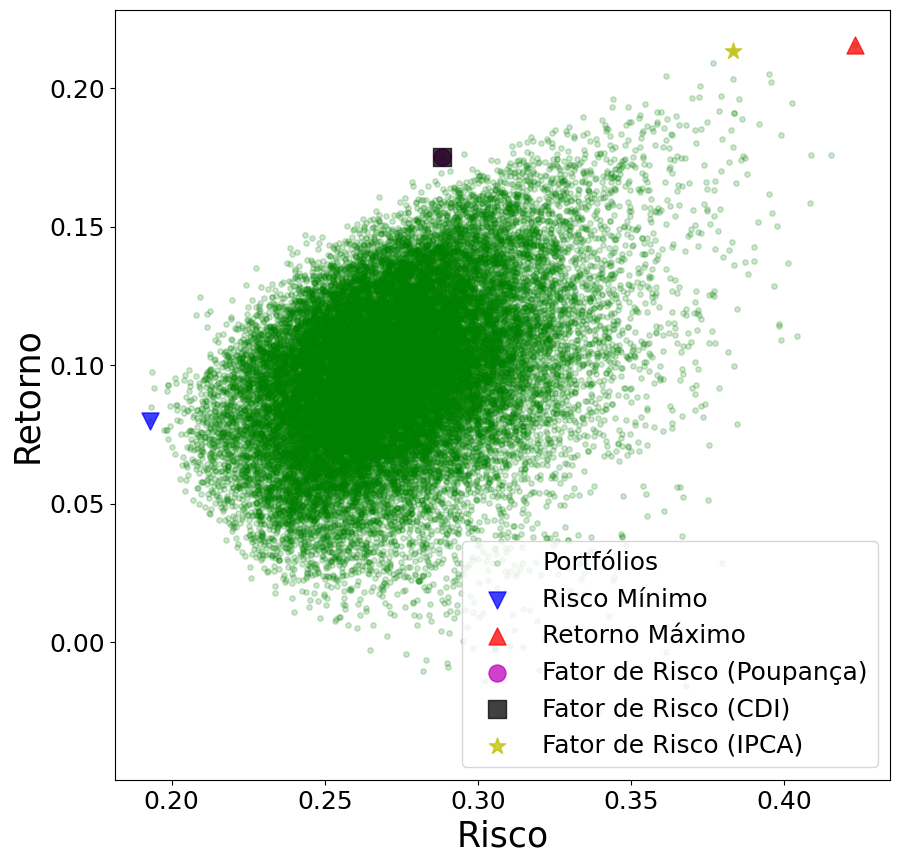

In [95]:
# Plotando o portfólio com volatilidade mínima e o com lucro máximo
plt.subplots(figsize=[10,10])
xx = portfolios['Risco']
yy = portfolios['Retorno']
plt.scatter(xx, yy ,                                    c='g',     marker='o', s=15,  alpha=0.2,  label = 'Portfólios');
plt.scatter(min_vol_port['Risco'], min_vol_port['Retorno'], c='b', marker='v', s=150, alpha=0.75, label = 'Risco Mínimo');
plt.scatter(max_ret_port['Risco'], max_ret_port['Retorno'], c='r', marker='^', s=150, alpha=0.75, label = 'Retorno Máximo');
plt.scatter(opt_ris_por0['Risco'], opt_ris_por0['Retorno'], c='m', marker='o', s=150, alpha=0.75, label = 'Fator de Risco (Poupança)');
plt.scatter(opt_ris_por1['Risco'], opt_ris_por1['Retorno'], c='k', marker='s', s=150, alpha=0.75, label = 'Fator de Risco (CDI)');
plt.scatter(opt_ris_por2['Risco'], opt_ris_por2['Retorno'], c='y', marker='*', s=150, alpha=0.75, label = 'Fator de Risco (IPCA)');
plt.xlabel('Risco',  fontsize=25)
plt.ylabel('Retorno',fontsize=25)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.legend(loc = 'best', fontsize=18);

#### Fit polinomial para extrair a curva de fronteira eficiente

In [96]:
# fit simples para extrair a curva de fronteira eficiente

# selecionando alguns pontos da fronteira
x = np.array([min_vol_port['Risco'], opt_ris_por0['Risco'], opt_ris_por1['Risco'], opt_ris_por2['Risco']])
y = np.array([min_vol_port['Retorno'], opt_ris_por0['Retorno'], opt_ris_por1['Retorno'], opt_ris_por2['Retorno']])

# Obs: vamos fazer o fit polinomial com grau "g" de x em função de y, pois o contrário não é função
g = 2
z = np.polyfit(y, x, g) # y em função de x
f = np.poly1d(z)

# criando a curva x's e y's após o fit e calibrando os limites
y_new = np.linspace(y[0] - 0.05, y[-1]+ 0.02, 50)
x_new = f(y_new)

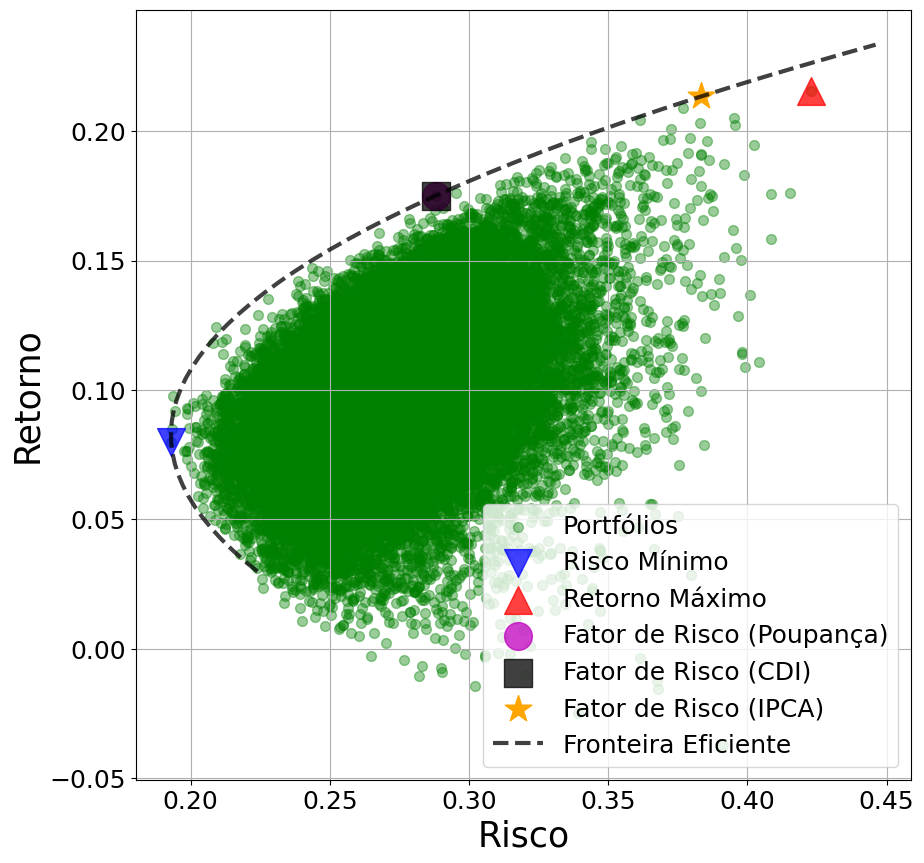

In [97]:
# Plotando novamente com a fronteira eficiente explícita
plt.subplots(figsize=[10,10])
xx = portfolios['Risco']
yy = portfolios['Retorno']
s1 = 400
plt.scatter(xx, yy ,                                    c='g',     marker='o', s=50, alpha=0.4,  label = 'Portfólios');
plt.scatter(min_vol_port['Risco'], min_vol_port['Retorno'], c='b', marker='v', s=s1, alpha=0.75, label = 'Risco Mínimo');
plt.scatter(max_ret_port['Risco'], max_ret_port['Retorno'], c='r', marker='^', s=s1, alpha=0.75, label = 'Retorno Máximo');
plt.scatter(opt_ris_por0['Risco'], opt_ris_por0['Retorno'], c='m', marker='o', s=s1, alpha=0.75, label = 'Fator de Risco (Poupança)');
plt.scatter(opt_ris_por1['Risco'], opt_ris_por1['Retorno'], c='k', marker='s', s=s1, alpha=0.75, label = 'Fator de Risco (CDI)');
plt.scatter(opt_ris_por2['Risco'], opt_ris_por2['Retorno'], c='orange', marker='*', s=s1, alpha=1,    label = 'Fator de Risco (IPCA)');
dv = 0.000 # pequeno deslocamento vertical
plt.plot(x_new, y_new + dv, '--', c='k', linewidth=3, alpha=0.75, label = 'Fronteira Eficiente')
plt.xlabel('Risco',  fontsize=25)
plt.ylabel('Retorno',fontsize=25)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.grid()
plt.legend(loc = 'best', fontsize=18);

In [98]:
# Importando pacotes úteis para a parte quântica (Qiskit >= 1.2; também funciona com a série 2.x)
import scipy.optimize
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector

## Otimização Revisitada - Abordagem restrita binária
Resolver o seguinte problema de otimização: \begin{split}\begin{aligned} \min_{x \in \{0, 1\}^n} q x^T \sigma x - \mu^T x\\ \text{com a restrição: } 1^T x = B \end{aligned}\end{split}
onde:
- $x \in \{0,1\}^n$ denota o vetor de variáveis ​​de decisão binárias, que indicam quais ativos escolher ($x = 1$) e quais não escolher ($x =0$),
- $\mu \in \mathbf{R}^n$ define os retornos esperados para os ativos, 
- $\sigma \in \mathbf{R}^{n\times n}$ especifica a matriz de covariância entre os ativos,
- $q>0$ controla o apetite de risco do gestor do portfólio,
- e $B$ denota o orçamento, neste caso, o número de ativos a serem selecionados dentre $n$ disponíveis.

Observações:

1 - simplificações assumidas: i) todos os ativos tem o mesmo preço normalizado como $1$ (pensando no log dos preços, não parece uma simplificação tão absurda), ii) o orçamento total deve ser gasto, ou seja, é necessário selecionar exatamente $B$ ativos. 

2- $q$ pode ser visto como uma medida do apetite ao risco pois, ao aumentar $q$, precisamos de maiores retornos para o alcançar o mínimo da função objetiva, o que, pela Fronteira Eficiente, exige maiores riscos!

3- A restrição $1^T x = B$ pode ser imaginada como oriunda de um termo de penalidade do tipo $\alpha (1^T x - B)^2$ incluído explicitamente na função objetiva. Ou seja, o problema com a restrição acima é idêntico à otimização do seguinte:

\begin{split}\begin{aligned} \min_{x \in \{0, 1\}^n} q x^T \sigma x - \mu^T x + \alpha (1^T x - B)^2  \end{aligned}\end{split} 
pois considerando $\alpha >0$, a menor contribuição do termo de regularização ocorre quando $1^T x = B$.

4- O problema resultante pode ser mapeado para um hamiltoniano cujo estado fundamental corresponde à solução ótima.

Referência: https://qiskit.org/documentation/finance/tutorials/01_portfolio_optimization.html

Essa secção mostra como usar o Variational Quantum Eigensolver (VQE) e o Quantum Approximate Optimization Algorithm (QAOA) para encontrar a solução ideal para um determinado conjunto de parâmetros.



## Quantum Approximate Optimization Algorithm (QAOA)

In [99]:
mu   = ind_er.to_numpy()      # Retorno
cov  = cov_matrix.to_numpy()  # Covariança

In [115]:
# CFG
num_assets = n_atv#4
num_qubits = n_atv
num_layers = 8
gamma_size = num_layers
beta_size  = num_layers
penalty   = num_assets        # Estabelece uma escala de penalidade
#
q          = 0.5              # Apetitive ao risco
B          = 5  # Orçamento
l          = 1                # Escala de penalidade

# Métodos de Computação Quântica - Qiskit

> **Nota sobre a atualização (Qiskit ≥ 1.2, Python 3.12).** Os módulos `qiskit.aqua`, `qiskit.optimization` e
> `qiskit.finance.applications.ising`, usados na versão original deste notebook, não existem mais no Qiskit.
> Por isso, aqui montamos **diretamente com o pacote `qiskit`** o Hamiltoniano de Ising do portfólio, o circuito do
> QAOA e o ansatz do VQE, e usamos o `scipy` (COBYLA) como otimizador clássico. O simulador é o `Statevector`
> (exato, sem ruído de amostragem), equivalente ao antigo `statevector_simulator`.

In [116]:
def index_to_selection(i, num_assets):
    """Converte o índice i de um estado da base computacional no vetor de seleção x.
    Convenção do Qiskit: o qubit k corresponde ao k-ésimo bit de i (qubit 0 = bit menos significativo)."""
    return np.array([(i >> k) & 1 for k in range(num_assets)])


def portfolio_value(x, mu, sigma, q, budget, penalty):
    """Função objetivo (QUBO):  q x^T Σ x - μ^T x + penalty (1^T x - B)^2"""
    x = np.asarray(x, dtype=float)
    return q * x @ sigma @ x - mu @ x + penalty * (x.sum() - budget) ** 2


def portfolio_ising(mu, sigma, q, budget, penalty):
    """QUBO -> Hamiltoniano de Ising, usando x_k = (1 - Z_k)/2  (|1> <-> Z = -1).

    Devolve (qubitOp, h, J) tais que  qubitOp = offset + sum_i h_i Z_i + sum_{i<j} J_ij Z_i Z_j.
    O termo constante (offset) já está incluído em qubitOp: assim, <H> é exatamente o valor da função objetivo."""
    n = len(mu)
    A = q * sigma + penalty * np.ones((n, n))          # parte quadrática:  x^T A x
    b = -mu - 2 * penalty * budget * np.ones(n)        # parte linear:      b^T x
    offset = penalty * budget ** 2                     # parte constante
    h, J = np.zeros(n), {}
    for i in range(n):                                 # x_i^2 = x_i  ->  (1 - Z_i)/2
        offset += (A[i, i] + b[i]) / 2
        h[i]   -= (A[i, i] + b[i]) / 2
    for i in range(n):
        for j in range(i + 1, n):
            a = A[i, j] + A[j, i]                      # coeficiente de x_i x_j = (1 - Z_i - Z_j + Z_i Z_j)/4
            offset += a / 4
            h[i]   -= a / 4
            h[j]   -= a / 4
            J[(i, j)] = a / 4
    termos = [("Z", [i], h[i]) for i in range(n)] + [("ZZ", [i, j], c) for (i, j), c in J.items()]
    qubitOp = SparsePauliOp.from_sparse_list(termos, num_qubits=n) + SparsePauliOp("I" * n, coeffs=[offset])
    return qubitOp.simplify(), h, J

In [117]:
qubitOp, h_ising, J_ising = portfolio_ising(mu, cov, q, B, penalty)

# Checagem: a diagonal do Hamiltoniano tem de coincidir com a função objetivo para todas as 2^n bitstrings
energias = np.array([portfolio_value(index_to_selection(i, num_assets), mu, cov, q, B, penalty)
                     for i in range(2 ** num_assets)])
assert np.allclose(qubitOp.to_matrix(sparse=True).diagonal().real, energias)

qubitOp

SparsePauliOp(['IIIIIZ', 'IIIIZI', 'IIIZII', 'IIZIII', 'IZIIII', 'ZIIIII', 'IIIIZZ', 'IIIZIZ', 'IIZIIZ', 'IZIIIZ', 'ZIIIIZ', 'IIIZZI', 'IIZIZI', 'IZIIZI', 'ZIIIZI', 'IIZZII', 'IZIZII', 'ZIIZII', 'IZZIII', 'ZIZIII', 'ZZIIII', 'IIIIII'],
              coeffs=[11.95887677+0.j, 12.11183043+0.j, 12.1229085 +0.j, 12.01311813+0.j,
 12.02256813+0.j, 12.06054163+0.j,  3.00009303+0.j,  3.00012281+0.j,
  3.00003297+0.j,  3.00002713+0.j,  3.00004483+0.j,  3.00013274+0.j,
  3.00003342+0.j,  3.00002549+0.j,  3.00005071+0.j,  3.00005681+0.j,
  3.00003434+0.j,  3.00007238+0.j,  3.00001417+0.j,  3.00002081+0.j,
  3.00002685+0.j, 32.70936794+0.j])

In [118]:
# Imprimir resultado de forma elegante
sigma  = cov
budget = B

def print_result(probabilities):
    """`probabilities`: vetor com a probabilidade de cada bitstring (índice = inteiro da bitstring)."""
    selection = index_to_selection(int(np.argmax(probabilities)), num_assets)
    value = portfolio_value(selection, mu, sigma, q, budget, penalty)
    print('Solução ótima: vetor {}, valor {:.4f}'.format(selection, value))

    i_sorted = np.argsort(probabilities)[::-1]
    print('\n----------------- Resultados ---------------------')
    print('vetor\t\tvalor\t\tprobabilidade')
    print('---------------------------------------------------')
    for i in i_sorted:
        x = index_to_selection(i, num_assets)
        value = portfolio_value(x, mu, sigma, q, budget, penalty)
        probability = probabilities[i]
        print('%10s\t%.4f\t\t%.4f' %(x, value, probability))

In [119]:
# Solução "clássica" exata (substitui o antigo NumPyMinimumEigensolver):
# como o Hamiltoniano é diagonal na base computacional, o estado fundamental é a bitstring de menor energia.
prob_exata = np.zeros(2 ** num_assets)
prob_exata[np.argmin(energias)] = 1.0

print_result(prob_exata)

Solução ótima: vetor [0 1 1 1 1 1], valor -0.6626

----------------- Resultados ---------------------
vetor		valor		probabilidade
---------------------------------------------------
[0 1 1 1 1 1]	-0.6626		1.0000
[1 1 1 1 1 1]	5.4203		0.0000
[1 0 1 1 1 1]	-0.3567		0.0000
[0 0 1 1 1 1]	5.5608		0.0000
[1 1 0 1 1 1]	-0.3347		0.0000
[0 1 0 1 1 1]	5.5829		0.0000
[1 0 0 1 1 1]	5.8888		0.0000
[0 0 0 1 1 1]	23.8068		0.0000
[1 1 1 0 1 1]	-0.5538		0.0000
[0 1 1 0 1 1]	5.3635		0.0000
[1 0 1 0 1 1]	5.6694		0.0000
[0 0 1 0 1 1]	23.5870		0.0000
[1 1 0 0 1 1]	5.6914		0.0000
[0 1 0 0 1 1]	23.6092		0.0000
[1 0 0 0 1 1]	23.9151		0.0000
[0 0 0 0 1 1]	53.8332		0.0000
[1 1 1 1 0 1]	-0.5348		0.0000
[0 1 1 1 0 1]	5.3824		0.0000
[1 0 1 1 0 1]	5.6883		0.0000
[0 0 1 1 0 1]	23.6059		0.0000
[1 1 0 1 0 1]	5.7103		0.0000
[0 1 0 1 0 1]	23.6280		0.0000
[1 0 0 1 0 1]	23.9339		0.0000
[0 0 0 1 0 1]	53.8520		0.0000
[1 1 1 0 0 1]	5.4912		0.0000
[0 1 1 0 0 1]	23.4085		0.0000
[1 0 1 0 0 1]	23.7144		0.0000
[0 0 1 0 0 1]	53.63

# QAOA - Qiskit

In [122]:
def qaoa_circuit(h, J, p):
    """Circuito do QAOA com p camadas:  |+>^n  ->  [ U(B, β_k) U(C, γ_k) ] (k = 0..p-1).
    Parâmetros: γ_k = theta[k] e β_k = theta[p + k]."""
    n = len(h)
    theta = ParameterVector('θ', 2 * p)
    qc = QuantumCircuit(n)
    qc.h(range(n))                                  # estado inicial |+>^n
    for k in range(p):
        gamma, beta = theta[k], theta[p + k]
        for (i, j), c in J.items():
            qc.rzz(2 * gamma * c, i, j)             # exp(-i γ J_ij Z_i Z_j)
        for i in range(n):
            qc.rz(2 * gamma * h[i], i)              # exp(-i γ h_i Z_i)
        qc.rx(2 * beta, range(n))                   # operador de mistura: exp(-i β X_i)
    return qc, list(theta)


def otimiza(circuito, theta, op, maxiter, seed, n_inicios=5, faixa=(-2 * np.pi, 2 * np.pi)):
    """Minimiza <ψ(θ)|op|ψ(θ)> com o COBYLA do SciPy, a partir de `n_inicios` pontos iniciais aleatórios
    (sementes seed, seed+1, ...). Devolve o melhor resultado e as probabilidades do estado final."""
    def custo(x):
        psi = Statevector.from_instruction(circuito.assign_parameters(dict(zip(theta, x))))
        return float(np.real(psi.expectation_value(op)))

    melhor = None
    for k in range(n_inicios):
        x0  = np.random.default_rng(seed + k).uniform(*faixa, size=len(theta))
        res = scipy.optimize.minimize(custo, x0, method='COBYLA', options={'maxiter': maxiter})
        if melhor is None or res.fun < melhor.fun:
            melhor = res
    psi = Statevector.from_instruction(circuito.assign_parameters(dict(zip(theta, melhor.x))))
    return melhor, psi.probabilities()


p_qaoa  = 6      # número de camadas do QAOA
maxiter = 1000    # iterações máximas do COBYLA (a versão original usava 250)
seed    = 3

circ_qaoa, theta_qaoa = qaoa_circuit(h_ising, J_ising, p_qaoa)
res_qaoa, prob_qaoa   = otimiza(circ_qaoa, theta_qaoa, qubitOp, maxiter=maxiter, seed=seed)

print('Energia esperada <H> = {:.4f}  (mínimo exato: {:.4f})\n'.format(res_qaoa.fun, energias.min()))
print_result(prob_qaoa)

Energia esperada <H> = 3.5418  (mínimo exato: -0.6626)

Solução ótima: vetor [0 1 1 1 1 1], valor -0.6626

----------------- Resultados ---------------------
vetor		valor		probabilidade
---------------------------------------------------
[0 1 1 1 1 1]	-0.6626		0.2990
[1 1 1 0 1 1]	-0.5538		0.1627
[1 1 1 1 0 1]	-0.5348		0.1465
[1 1 1 1 1 0]	-0.4590		0.0924
[1 0 0 1 1 1]	5.8888		0.0615
[0 1 0 1 1 1]	5.5829		0.0373
[0 0 1 1 1 1]	5.5608		0.0368
[0 1 1 0 1 1]	5.3635		0.0143
[0 1 1 1 1 0]	5.4583		0.0130
[1 0 1 1 1 1]	-0.3567		0.0127
[1 1 1 1 1 1]	5.4203		0.0123
[0 1 1 0 0 1]	23.4085		0.0109
[1 1 0 1 1 0]	5.7862		0.0098
[0 1 1 1 0 1]	5.3824		0.0086
[1 0 1 1 1 0]	5.7642		0.0066
[0 1 1 0 1 0]	23.4844		0.0062
[0 1 1 1 0 0]	23.5034		0.0056
[1 1 1 1 0 0]	5.5860		0.0054
[1 1 0 1 1 1]	-0.3347		0.0042
[1 1 1 0 0 0]	23.6120		0.0039
[1 1 1 0 1 0]	5.5670		0.0037
[1 0 1 0 0 0]	53.8354		0.0026
[1 1 0 0 0 0]	53.8576		0.0024
[1 0 0 1 0 0]	54.0552		0.0022
[0 0 1 0 1 1]	23.5870		0.0022
[1 1 0 0 1 1]	5.6914		0

<font color='blue'>Observe como o "solver" penaliza carteiras com número de ações diferentes do orçamento == 2. Por exemplo, veja o valor da função objetivo para [0 0 0 0] e [1 1 1 1].</font>

# VQE - Qiskit

In [123]:
def ansatz_ry_cz(n, reps):
    """Ansatz do VQE: camadas de RY seguidas de CZ com emaranhamento total, repetidas `reps` vezes
    (equivale ao antigo TwoLocal(n, 'ry', 'cz', reps=reps, entanglement='full'))."""
    theta = ParameterVector('θ', n * (reps + 1))
    qc = QuantumCircuit(n)
    for r in range(reps + 1):
        for i in range(n):
            qc.ry(theta[r * n + i], i)
        if r < reps:
            for i in range(n):
                for j in range(i + 1, n):
                    qc.cz(i, j)
    return qc, list(theta)


reps    = 12      # repetições do ansatz
maxiter = 500     # iterações máximas do COBYLA
seed    = 215

circ_vqe, theta_vqe = ansatz_ry_cz(num_qubits, reps)
res_vqe, prob_vqe   = otimiza(circ_vqe, theta_vqe, qubitOp, maxiter=maxiter, seed=seed)

print('Energia esperada <H> = {:.4f}  (mínimo exato: {:.4f})\n'.format(res_vqe.fun, energias.min()))
print_result(prob_vqe)

Energia esperada <H> = 1.6644  (mínimo exato: -0.6626)

Solução ótima: vetor [1 1 1 1 1 0], valor -0.4590

----------------- Resultados ---------------------
vetor		valor		probabilidade
---------------------------------------------------
[1 1 1 1 1 0]	-0.4590		0.3630
[1 0 1 1 1 1]	-0.3567		0.2682
[1 1 1 0 1 0]	5.5670		0.0769
[1 1 0 1 1 1]	-0.3347		0.0679
[0 0 1 1 1 1]	5.5608		0.0466
[1 1 0 0 1 1]	5.6914		0.0415
[1 1 1 1 0 1]	-0.5348		0.0343
[1 1 1 0 0 1]	5.4912		0.0171
[0 1 1 1 0 1]	5.3824		0.0141
[1 1 1 1 1 1]	5.4203		0.0100
[1 0 1 0 1 1]	5.6694		0.0091
[0 1 0 1 1 1]	5.5829		0.0079
[1 1 0 1 1 0]	5.7862		0.0067
[1 0 1 1 0 0]	23.8092		0.0066
[1 0 1 1 1 0]	5.7642		0.0057
[1 1 1 0 1 1]	-0.5538		0.0025
[1 1 0 1 0 1]	5.7103		0.0025
[0 1 1 1 1 0]	5.4583		0.0022
[0 1 1 1 0 0]	23.5034		0.0021
[1 1 1 0 0 0]	23.6120		0.0016
[1 1 0 0 0 1]	23.7365		0.0016
[0 1 1 0 0 1]	23.4085		0.0013
[1 0 0 1 0 1]	23.9339		0.0012
[0 0 0 1 1 0]	53.9281		0.0011
[0 1 1 0 1 1]	5.3635		0.0010
[0 0 0 1 1 1]	23.8068		0.

<font color='blue'>Observe como o "solver" também penaliza carteiras com número de ações diferentes do orçamento == 2. Por exemplo, verifique o valor da função objetivo para [0 0 0 0] e [1 1 1 1].</font>

# Métodos de Computação Quântica com o Atos QLM

O ATOS Quantum Learning Machine (QLM) é um ambiente de teste para a computação quântica desenvolvida pela empresa francesa ATOS e adquirida pelo SENAI CIMATEC para o desenvolvimento de algoritmos quânticos no Centro de Computação Quântica da América Latina. O dispositivo é capaz de simular até 35 qubits e inclui a simulação de ruídos, emulando a arquitetura de computadores quânticos reais.

O QLM também possui interoperabilidade com outras frameworks de computação quântica, o que possibilita o uso de computadores quânticos através da plataforma. Além disso, o myQLM, framework disponibilizado gratuitamente, possibilita também o desenvolvimento e simulação de algoritmos quânticos por usuários domésticos, podendo sker instalado em seus computadores. Por sua completeza, a utilização do QLM para o desenvolvimento de algoritmos de computação quântica se torna interessante, podendo ser utilizado em diferentes etapas do desenvolvimento de algoritmos quânticos.

Para a implementação do QAOA e uma investigação da qualidade das soluções, ver nosso outro notebook disponível em: 

https://github.com/askery/computacao-quantica-aplicada-ao-mercado-financeiro/blob/main/QAOA_myQLM.ipynb

# Notas sobre o QAOA

O QAOA é um algoritmo variacional da computação quântica, desenvolvido por \cite{faihi2014}, adequado para resolver problemas de otimização combinatória. Nesta seção, apresentaremos um problema de otimização combinatória que pode ser modelado como um modelo ferromagnético popular na mecânica estatística: o \textit{Modelo de Ising} (ou \textit{Hamiltoniano de Ising}). O algoritmo consiste em modelar a função objetivo (F.O.) como um \textit{Hamiltoniano de Ising} e transformá-la em operadores unitários, aplicar tais operadores em um estado de entrada, medir os valores esperados, atualizar os parâmetros e repetir o processo até que a função custo seja minimizada. Quando a energia da F.O. é minimizada, a distribuição de probabilidades (obtida após a medição da função de onda $|\psi\rangle$ com os parâmetros ótimos) apresenta uma ocorrência maior do autoestado de $|\psi\rangle$ que fornece a melhor configuração para o problema. 

### Modelo de Ising

O modelo do comportamento de materiais ferromagnéticos pode ser descrito pelo \textit{Hamiltoniano de Ising}. O modelo representa uma cadeia de partículas de spin 1/2, que interagem em pares, sendo que cada constituinte está sujeito à um campo magnético de magnitude $h_i$. Como partículas de spin 1/2 podem assumir apenas duas direções de momento de dipolo ("up" e "down") a interação entre cada par de partículas fornece uma energia (positiva ou negativa) de acordo com as orientações dos spins. Para encontrar a configuração dos momentos de dipolo que fornece o menor valor de energia possível do sistema, a seguinte função objetivo deve ser minimizada: 

\begin{equation} 
    C(z) = - \sum_{<ij>}^{}z_iz_j - \sum_{i}^{}h_iz_i .
\end{equation} 

As variáveis $z_i$ da função objetivo podem assumir apenas valores unitários, sejam eles positivos ou negativos, ou seja, $z_i \in \{-1,+1\}$. As variáveis podem ser escritas como operadores de Pauli-Z ($\sigma_z$), já que $\pm 1$ são autovalores de $\sigma_z$, associados às autofunções de spin das partículas.

### Operador de Fase

Para que seja possível mapear um problema de variáveis binárias $z_i$ para um problema de otimização de autovalores, uma estratégia é substituir as variáveis $z_i \in \{-1,+1\}$ por operadores unitários (que possuem autovalores $\lambda \in \{-1,+1\}$). Diante disso, é possível criar um Operador de Fase que representa as interações entre as partículas adjacentes, bem como a resposta das partículas ao campo magnético aplicado. Trata-se de escrever a função objetivo do problema como um operador unitário para que possa ser aplicada diretamente no circuito. Como visto, o operador descrito na Equação \ref{fo_ising} é não-unitário, visto que não satisfaz o critério da Equação 7. Contudo, cada termo da soma (negligenciando os coeficientes) é um operador unitário. Para descrever este Hamiltoniano define-se o Operador Gamma através da relação


\begin{equation} 
    U(C,\gamma)=e^{-i\gamma C(Z)}=e^{i\gamma\sum_{<ij>}^{}Z_iZ_j + i\gamma\sum_{i}^{}h_iZ_i} .
\end{equation}


Como $C(z)$ é expressa em termos dos operadores Pauli-Z e o produto tensorial entre eles geram matrizes diagonais, $U(C,\gamma)$ também é uma matriz diagonal (porém unitária), onde o parâmetro $\gamma$ é um dos parâmetros variacionais usados no QAOA. Desse modo, o operador $U(C,\gamma)$ pode ser escrito como a operação unitária

\begin{equation} 
    U(C,\gamma)=\prod_{<ij>}^{}e^{i\gamma Z_iZ_j}\prod_{i=0}^{N}e^{i\gamma h_iZ_i} .
\end{equation}

Esse operador (assim como produtos tensoriais entre matrizes de Pauli-Z) apresenta a forma de  uma matriz diagonal, onde os elementos da diagonal são exponenciais complexas que adicionam fases no estado quântico no qual é aplicado.

### Operador de Mistura

O operador $U(B,\beta)$ é aplicado com o objetivo de misturar as amplitudes (gerando interferências destrutivas e construtivas) possibilitando explorar melhor o espaço de busca e aumentando as chances de encontrar, com maior precisão, o ponto ótimo global da função objetivo. O Operador de Mistura pode ser descrito, matematicamente, como


\begin{equation} 
    U(B,\beta) = e^{-i\beta \sum_{j=0}^{N} X_j} \equiv \prod_{j=0}^{N}e^{-i\beta X_j}.
\end{equation}


Tal operador pode ser construído utilizando apenas operações de rotação em \textit{qubits} individuais do tipo RX. Contudo,a eficiência desse operador está diretamente ligada ao tempo de convergência e à acurácia do algoritmo. A Equação \ref{mix} descreve o operador em sua forma mais simples, representado apenas como rotações em torno do eixo $x$ da \textit{Esfera de Bloch}. 

### Função objetivo do QAOA: Medindo Valores Esperados
As operações unitárias apresentadas nas subseções anteriores podem ser representadas como diagramas de circuitos quânticos. No QAOA, cada conjunto das operações em questão são conhecidas como \textit{layers}. A $i$-ésima \textit{layer} do circuito pode ser escrita como


\begin{equation} 
    U(\gamma_i,\beta_i) = U(B,\beta_i)U(C,\gamma_i),
\end{equation}


e, portanto, a sequência desses operadores representa o operador geral do QAOA. Quanto maior o número de \textit{layers}, maior o número de parâmetros do circuito e, consequentemente, maior a acurácia do resultado. Assim como no VQE, a função objetivo do QAOA também é um valor esperado. A diferença entre eles é que, no VQE, utiliza-se um ansatz genérico e no QAOA, por sua vez, o ansatz é construído à partir da função objetivo. A atuação do operador geral do QAOA sobre o estado de entrada $|s\rangle$ pode ser considerada da seguinte maneira:
\begin{equation} 
    |\vec{\gamma},\vec{\beta} \rangle = (U(B,\beta_n)U(C,\gamma_n))...(U(B, \beta_1)U(C,\gamma_1))(U(B,\beta_0)U(C,\gamma_0))|s\rangle.
\end{equation}
Como é de interesse encontrar a configuração de menor energia para o hamiltoniano, a função objetivo do problema é, novamente, a função dos valores esperados de energia, que se minimizada, retorna o menor autovalor de energia do sistema. A função objetivo do problema pode ser expressa como

\begin{equation}
    \langle C(Z) \rangle \equiv \langle\vec{\gamma},\vec{\beta}|C(Z)|\vec{\gamma},\vec{\beta} \rangle.
\end{equation}
Como visto nos capitulos anteriores, o valor esperado de energia também pode ser escrito como um valor médio. Quando o estado quântico é preparado e medido uma quantidade suficiente de vezes, a distribuição de probabilidades obtida nos possibilita calcular o valor esperado como a soma da quantidade de vezes que cada autoestado da função de onda foi medido, multiplicada por suas respectivas energias associadas. Portanto, a função objetivo também pode ser escrita como
\begin{equation} 
    \langle\vec{\gamma},\vec{\beta}|C(Z)|\vec{\gamma},\vec{\beta} \rangle = E_0\alpha_0\langle\vec{\gamma},\vec{\beta}|0\rangle + E_1\alpha_1\langle\vec{\gamma},\vec{\beta}|1\rangle + E_2\alpha_2\langle\vec{\gamma},\vec{\beta}|2\rangle + ... + E_n\alpha_n\langle\vec{\gamma},\vec{\beta}|n\rangle =  \sum_{i=0}^{n}E_ip_i.
\end{equation}


Os parâmetros variacionais, $\gamma$ e $\beta$, são atualizados iterativamente através de métodos clássicos de otimização até que o menor autovalor de energia seja encontrado. Por se tratar de problemas de otimização combinatória, o interesse do problema é no autoestado da base computacional associado ao menor autovalor, que é composto pela \textit{bitstring} formada pela configuração ótima do problema. 


Como visto, o QAOA pode ser usado para encontrar a configuração que minimiza a energia do \textit{Hamiltoniano de Ising}. Por se tratar de um problema de otimização combinatória, percebe-se que o algoritmo é um bom candidato a resolver problemas dessa natureza. 

### O Método Variacional da Mecânica Quântica
Como discutido no Capítulo 2, informações sobre um estado quântico podem ser obtidas por meio de um conjunto de medidas sobre o sistema. Embora nosso objetivo seja encontrar o menor autovalor de uma matriz, a função objetivo do problema é calculada através valor esperado da matriz em questão, visto que se uma função de onda parametrizada por um conjunto de parâmetros $\theta$ é criada, o princípio variacional nos garante que
\begin{equation}
    \langle \mathcal{H}_\theta \rangle \equiv \langle \psi_\theta | \mathcal{H}|\psi_\theta \rangle \geq \lambda_{min}.
\end{equation}

Portanto, se o espaço de busca é suficientemente grande e o objetivo do problema é minimizar o valor esperado da matriz $ \mathcal{H}$, existe um conjunto de parâmetros $\theta'$ que minimiza a função objetivo. Diante disso, podemos afirmar que uma boa e confiável aproximação para o menor autovalor $\lambda{min}$ da matriz $\mathcal{H}$ pode ser dada por

\begin{equation}
    \langle \mathcal{H}_{\theta'}\rangle_{min} \approx \lambda_{min}.
\end{equation}

Uma explicação intuitiva do método variacional pode ser apresentada da seguinte maneira: O valor esperado (ou valor médio) de uma grandeza, pode assumir infinitos valores entre os respectivos máximo e mínimo. Logo, o valor médio de um observável físico nunca será menor que seu autovalor mínimo e nunca será maior que seu autovalor máximo. 

# Perspectivas

Futuros trabalhos nesta linha de pesquisa envolvem a inclusão de ruídos nas etapas quânticas da simulação. Esses ruídos ocorrem naturalmente nos computadores quânticos atuais e induzem erros que ainda não podem ser controlados eficientemente. Dessa forma, ao reproduzir os resultados com a inclusão de ruídos será possível determinar o ponto de transição onde os níveis de ruídos de um computador quântico passa a permitir a aplicação do  QAOA para a otimização de portfólios. 

# Referências

[1] https://www.analyticsvidhya.com/blog/2021/04/portfolio-optimization-using-mpt-in-python/

[2] https://qiskit.org/documentation/finance/tutorials/01_portfolio_optimization.html 